### 상관분석 실정 (Correlation Analysis)
상관분석이란 두 수치형 변수 사이의 관계 방향과 강도를 파악하는 통계적 분석 방법이다.

예를들어 다음과 같은 질문에 답할 수 있다.
- 공부 시간이 길수록 시험 점수가 높아지는가
- 광고비가 증가할수록 매출도 증가하는가
- 나이가 많을수록 지불한 운임도 높아지는가

상관분석은 보통 다음 순서로 진행한다.
1. 데이터 확인 - 변수 유형, 이상치, 결측치 등 확인
2. 시각화 - 산점도로 관계의 형태 확인
3. 상관계수 선택 - 피어슨 또는 스피어만
4. 상관계수 계산 - 방향과 강도 확인
5. 결과 해석 - 실제 의미와 한계 검토

#### 상관계수 행렬 (Correlation Matrix)
지금까지 X-Y처럼 두 변수 사이의 상관계수를 확인했지만, 만약 변수가 5개, 10개, 20개 처럼 늘어난다면 어떻게 해야될까

그럴때는 상관계수 행렬을 사용해야한다.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = {
    "study_hours": [1, 2, 3, 4, 5, 6],
    "exam_score": [50, 55, 65, 70, 80, 90],
    "game_hours": [6, 5, 4, 3, 2, 1]
}

df = pd.DataFrame(data)

print(df)

# 전체 변수의 피어슨 상관계수 계산
corr_matrix = df.corr(method="pearson")
print(corr_matrix)


   study_hours  exam_score  game_hours
0            1          50           6
1            2          55           5
2            3          65           4
3            4          70           3
4            5          80           2
5            6          90           1
             study_hours  exam_score  game_hours
study_hours       1.0000      0.9941     -1.0000
exam_score        0.9941      1.0000     -0.9941
game_hours       -1.0000     -0.9941      1.0000


In [7]:
# 만약 시험 점수와 다른 변수들간의 피어슨 상관관계를 확인하고 싶다면 아래처럼 작성
print(corr_matrix["exam_score"])

# .sort_values(asending=True)를 써서 정렬을 사용할 수도 있다.
print(corr_matrix["exam_score"].sort_values(ascending=False))

# 자기 자신과의 상관계수는 무조건 1이니까 제외해서 보여주는것이 좋다.
# drop()
print(corr_matrix["exam_score"].sort_values(ascending=False).drop("exam_score"))

study_hours    0.9941
exam_score     1.0000
game_hours    -0.9941
Name: exam_score, dtype: float64
exam_score     1.0000
study_hours    0.9941
game_hours    -0.9941
Name: exam_score, dtype: float64
study_hours    0.9941
game_hours    -0.9941
Name: exam_score, dtype: float64


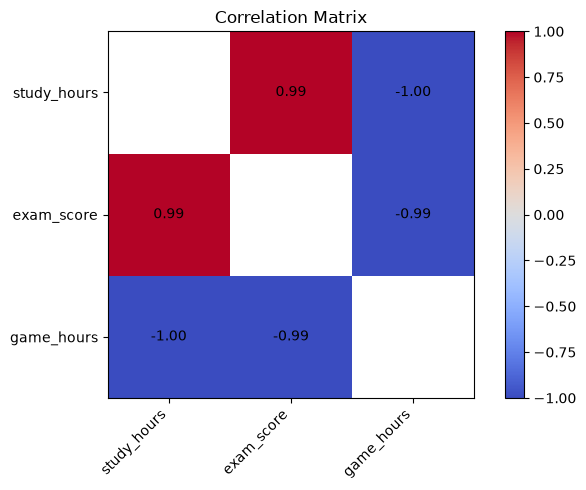

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 피어슨 상관행렬 생성
corr_matrix = df.corr(method="pearson", numeric_only=True)

# 2. 대각선 마스크 생성
mask = np.eye(len(corr_matrix), dtype=bool)

# 3. 자기 자신과의 상관계수 제거
corr_matrix = corr_matrix.mask(mask)

# 4. 그래프 생성
fig, ax = plt.subplots(figsize=(7, 5))

# 5. 히트맵 생성
im = ax.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# 6. 축 눈금 설정
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))

# 7. 축 이름 설정
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.index)

# 8. 상관계수 표시
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):

        value = corr_matrix.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j, i,
                f"{value:.2f}",
                ha="center",
                va="center"
            )

# 9. 색상 범례
plt.colorbar(im, ax=ax)

# 10. 제목 및 출력
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [25]:
# 타이타닉 데이터셋을 이용해서 상관계수 확인과 시각화 하기

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../datasets/titanic.csv")

columns = ["age", "fare", "pclass", "sibsp", "parch"]

analysis_df = df[columns].copy()
pearson_corr = analysis_df.corr(method="pearson")
spearman_corr = analysis_df.corr(method="spearman")

print("피어슨 상관계수")
print(pearson_corr)
print("\n")
print("스피어만 상관계수")
print(spearman_corr)

피어슨 상관계수
             age      fare    pclass     sibsp     parch
age     1.000000  0.096067 -0.369226 -0.308247 -0.189119
fare    0.096067  1.000000 -0.549500  0.159651  0.216225
pclass -0.369226 -0.549500  1.000000  0.083081  0.018443
sibsp  -0.308247  0.159651  0.083081  1.000000  0.414838
parch  -0.189119  0.216225  0.018443  0.414838  1.000000


스피어만 상관계수
             age      fare    pclass     sibsp     parch
age     1.000000  0.135051 -0.361666 -0.182061 -0.254212
fare    0.135051  1.000000 -0.688032  0.447113  0.410074
pclass -0.361666 -0.688032  1.000000 -0.043019 -0.022801
sibsp  -0.182061  0.447113 -0.043019  1.000000  0.450014
parch  -0.254212  0.410074 -0.022801  0.450014  1.000000
